# 3. Exploratory Data Analysis (EDA)

EDA dilakukan untuk melihat komposisi kelas dan variasi indeks spektral sebelum membangun model. Kode berikut membuat visualisasi menggunakan Matplotlib.

## Distribusi Jumlah Piksel per Kelas

Diagram batang menghitung jumlah baris dataset untuk setiap `label_teks`. Urutan kelas diatur dari kelas dengan jumlah piksel terbanyak. Grafik ini membantu melihat apakah jumlah piksel antar kelas seimbang atau terdapat kelas yang lebih dominan.

Perlu diperhatikan bahwa grafik ini menghitung **piksel**, bukan poligon independen. Perbedaan jumlah piksel dapat mencerminkan ukuran atau jumlah area sampel, sehingga belum tentu sama dengan distribusi sampel yang dipakai dalam evaluasi model.

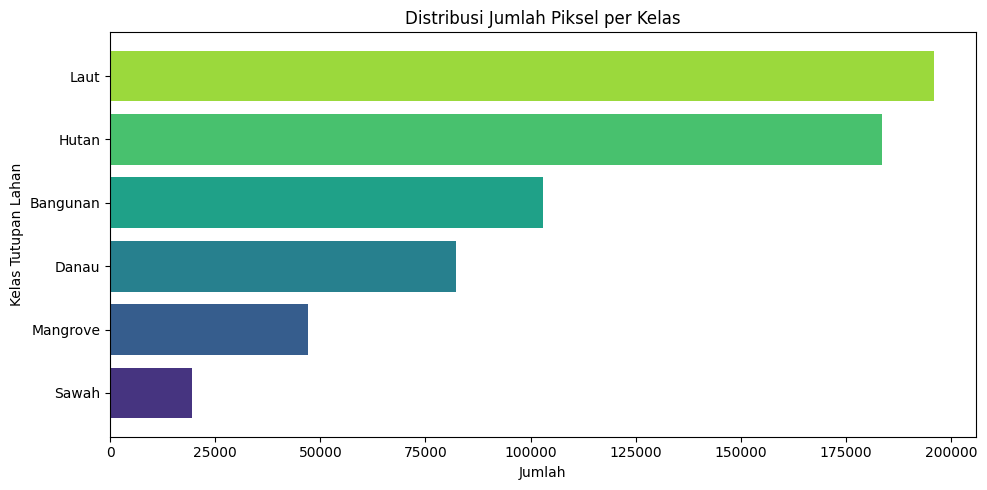

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

dataset_path = next(
    (
        candidate
        for folder in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            folder / "piksel_s2_JTM.csv",
            folder / "Tugas" / "UTS" / "piksel_s2_JTM.csv",
        )
        if candidate.is_file()
    ),
    None,
)
if dataset_path is None:
    raise FileNotFoundError("Dataset piksel_s2_JTM.csv tidak ditemukan.")

df = pd.read_csv(dataset_path)
jumlah_per_kelas = df["label_teks"].value_counts().sort_values()
warna_kelas = plt.cm.viridis(
    np.linspace(0.15, 0.85, len(jumlah_per_kelas))
)

plt.figure(figsize=(10, 5))
plt.barh(jumlah_per_kelas.index, jumlah_per_kelas.values, color=warna_kelas)
plt.title("Distribusi Jumlah Piksel per Kelas")
plt.xlabel("Jumlah")
plt.ylabel("Kelas Tutupan Lahan")
plt.tight_layout()
plt.show()

## Distribusi NDVI per Kelas

Boxplot membandingkan distribusi nilai `NDVI` untuk setiap kelas. Median, rentang antarkuartil, dan pencilan pada grafik dapat digunakan untuk menilai apakah nilai NDVI cenderung berbeda antar kelas serta seberapa besar tumpang tindihnya.

NDVI merupakan salah satu fitur, bukan satu-satunya dasar klasifikasi. Model juga menggunakan band spektral dan indeks lain yang dijelaskan pada bagian Data Understanding.

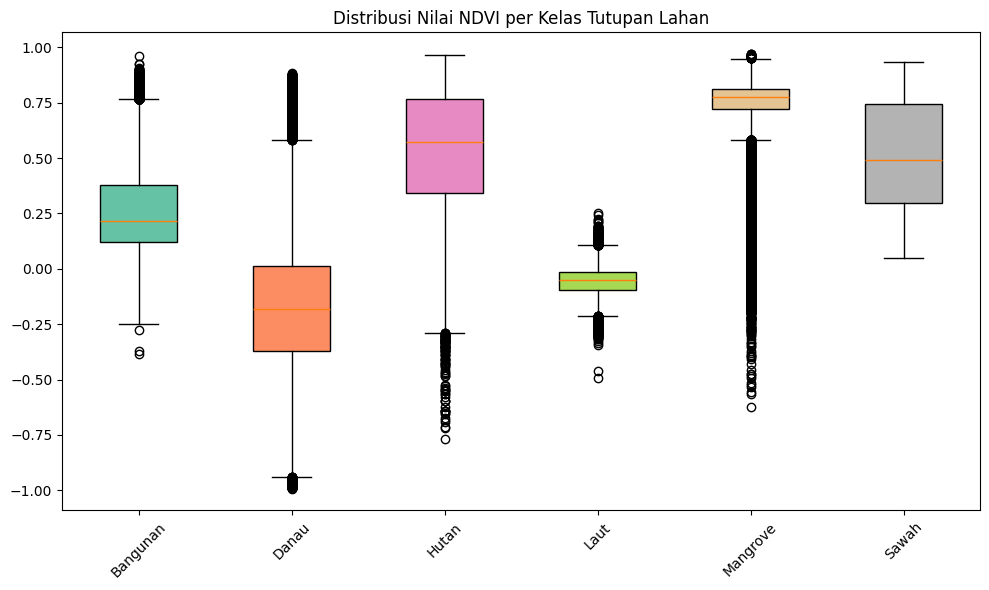

In [2]:
plt.figure(figsize=(10, 6))
urutan_kelas = sorted(df["label_teks"].dropna().unique())
nilai_ndvi = [
    df.loc[df["label_teks"] == kelas, "NDVI"].dropna()
    for kelas in urutan_kelas
]
boxplot = plt.boxplot(
    nilai_ndvi,
    tick_labels=urutan_kelas,
    patch_artist=True,
)
warna_box = plt.cm.Set2(np.linspace(0, 1, len(urutan_kelas)))
for kotak, warna in zip(boxplot["boxes"], warna_box):
    kotak.set_facecolor(warna)
plt.title("Distribusi Nilai NDVI per Kelas Tutupan Lahan")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Interpretasi

Kedua grafik bersifat eksploratif dan tidak dengan sendirinya menunjukkan hubungan sebab-akibat atau kinerja prediksi. Penilaian kinerja dilakukan terpisah pada bagian pemodelan dengan data uji tingkat poligon.